# Assignment: Global average budgets in the CESM pre-industrial control simulation

This notebook is part of [The Climate Laboratory](https://brian-rose.github.io/ClimateLaboratoryBook) by [Brian E. J. Rose](https://www.atmos.albany.edu/facstaff/brose/), University at Albany.

## Learning goals

Students completing this assignment will gain the following skills and concepts:

- Continued practice working with the Jupyter notebook
- Familiarity with atmospheric output from the CESM simulation
- More complete comparison of the global energy budget in the CESM control simulation to the observations
- Validation of the annual cycle of surface temperature against observations
- Opportunity to formulate a hypothesis about these global temperature variations
- Python programming skills: basic xarray usage: opening gridded dataset and taking averages

## Instructions

- In a local copy of this notebook (on the JupyterHub or your own device) **add your answers in additional cells**.
- **Complete the required problems** below. 
- Remember to set your cell types to `Markdown` for text, and `Code` for Python code!
- **Include comments** in your code to explain your method as necessary.
- Remember to actually answer the questions. **Written answers are required** (not just code and figures!)
- Submit your solutions in **a single Jupyter notebook** that contains your text, your code, and your figures.
- *Make sure that your notebook* ***runs cleanly without errors:***
    - Save your notebook
    - From the `Kernel` menu, select `Restart & Run All`
    - Did the notebook run from start to finish without error and produce the expected output?
    - If yes, save again and submit your notebook file
    - If no, fix the errors and try again.

## Problem 1: The global energy budget in the CESM control simulation

Compute the **global, time average** of each of the following quantities, and compare them to the observed values from the Trenberth and Fasullo (2012) figure in the course notes:

- Solar Radiation budget:
    - Incoming Solar Radiation, or Insolation
    - Reflected Solar Radiation at the top of atmosphere
    - Solar Radiation Reflected by Surface
    - Solar Radiation Absorbed by Surface
    - Solar Radiation Refelected by Clouds and Atmosphere *(you can calculate this as the difference between the reflected radiation at the top of atmosphere and reflected radiation at the surface)*
    - Total Absorbed Solar Radiation (ASR) at the top of atmosphere
    - Solar Radiation Absorbed by Atmosphere *(you can calculate this as the residual of your budget, i.e. what's left over after accounting for all other absorption and reflection)*
- Longwave Radiation budget:
    - Outgoing Longwave Radiation
    - Upward emission from the surface
    - Downwelling radiation at the surface
- Other surface fluxes:
    - "Thermals", or *sensible heat flux*. *You will find this in the field called `SHFLX` in your dataset.*
    - "Evapotranspiration", or *latent heat flux*. *You will find this in the field called `LHFLX` in your dataset.*
    
*Note we will look more carefully at atmospheric absorption and emission processes later. You do not need to try to calculate terms such as "Emitted by Atmosphere" or "Atmospheric Window"*

**Based on your results above, answer the following questions:**

- Is the CESM control simulation at (or near) **energy balance**? What does this suggest about whether the modeled climate is near equilibrium?
- Summarize in your own words what you think are the most important similarities and differences of the global energy budgets in the CESM simulation and the observations.

In [35]:
### Answers ### 
import xarray as xr

cesm_data_path = "http://thredds.atmos.albany.edu:8080/thredds/dodsC/CESMA/"

atm_control = xr.open_dataset(cesm_data_path + "cpl_1850_f19/concatenated/cpl_1850_f19.cam.h0.nc")

area_weight_factor = atm_control.gw / atm_control.gw.mean(dim='lat')

# Solar Radiation #

avg_SOLIN = (atm_control.SOLIN * area_weight_factor).mean(dim=("lat", "lon", "time"))
avg_FSUT = ((atm_control.SOLIN - atm_control.FSNT) * area_weight_factor).mean(dim=("lat", "lon", "time"))
avg_FSUS = ((atm_control.FSDS - atm_control.FSNS) * area_weight_factor).mean(dim=("lat", "lon", "time"))
avg_FSNS = (atm_control.FSNS * area_weight_factor).mean(dim=("lat", "lon", "time"))
avg_FSUCloudsAtm = avg_FSUT - avg_FSUS
avg_ASR = (atm_control.FSNT * area_weight_factor).mean(dim=("lat","lon", "time"))
avg_ASRatm = avg_SOLIN - avg_FSNS - avg_FSUT

print("Solar radiation budget:")
print("Insolation = %0.2f W m-2 (2004: 341.3 W m-2)" %avg_SOLIN)
print("Outgoing at TOA = %0.2f (2004: 101.9 W m-2)" %avg_FSUT)
print("Reflected by Surface = %0.2f (2004: 23 W m-2)" %avg_FSUS)
print("Absorbed by Surface = %0.2f (2004: 161 W m-2)" %avg_FSNS)
print("Reflected by Clouds and Atmosphere = %0.2f (2004: 79 W m-2)" %avg_FSUCloudsAtm)
print("Net at TOA (ASR) = %0.2f (2004: 239.4 W m-2)" %avg_ASR)
print("Absorbed by Atmosphere = %0.2f (2004: 78 W m-2)" %avg_ASRatm)

# Longwave Radiation # 
avg_OLR = (atm_control.FLUT * area_weight_factor).mean(dim=("lat","lon", "time"))
avg_FLUS = ((atm_control.FLNS + atm_control.FLDS)* area_weight_factor).mean(dim=("lat","lon", "time"))
avg_FLDS = (atm_control.FLDS * area_weight_factor).mean(dim=("lat","lon", "time"))

print("\nLongwave radiation budget:")
print("Outgoing at TOA = %0.2f (2004: 238.5 W m-2)" %avg_OLR)
print("Upward Emission at Surface = %0.2f (2004: 396 W m-2)" %avg_FLUS)
print("Downwelling at Surface = %0.2f (2004: 333 W m-2)" %avg_FLDS)

# Other #
avg_Thermals = (atm_control.SHFLX *area_weight_factor).mean(dim=("lat","lon", "time"))
avg_Evapo = (atm_control.LHFLX *area_weight_factor).mean(dim=("lat","lon", "time"))

print("\nOther:")
print("Thermals = %0.2f (2004: 17 W m-2)" %avg_Thermals)
print("Evapotranspiration = %0.2f (2004: 80 W m-2)" %avg_Evapo)

print("\nEnergy Balance:")
print("ASR - OLR = %0.5f W m-2" %(avg_ASR - avg_OLR))

Solar radiation budget:
Insolation = 340.31 W m-2 (2004: 341.3 W m-2)
Outgoing at TOA = 106.13 (2004: 101.9 W m-2)
Reflected by Surface = 24.57 (2004: 23 W m-2)
Absorbed by Surface = 161.38 (2004: 161 W m-2)
Reflected by Clouds and Atmosphere = 81.55 (2004: 79 W m-2)
Net at TOA (ASR) = 234.18 (2004: 239.4 W m-2)
Absorbed by Atmosphere = 72.80 (2004: 78 W m-2)

Longwave radiation budget:
Outgoing at TOA = 235.37 (2004: 238.5 W m-2)
Upward Emission at Surface = 395.45 (2004: 396 W m-2)
Downwelling at Surface = 335.28 (2004: 333 W m-2)

Other:
Thermals = 17.53 (2004: 17 W m-2)
Evapotranspiration = 83.00 (2004: 80 W m-2)

Energy Balance:
ASR - OLR = -1.19231 W m-2


### Problem 1 Answers

Based on the difference between OLR and ASR, the CESM model is not in energy balance. The OLR is greater than the ASR by about 1.2 W/m2, which means that the Earth system is emitting more than it is absorbing. This is different than the imbalance of the Trenberth and Fasullo analysis, where the Earth system is absorbing more than it is emitting, and will therefore heat up. These are not drastic imbalances, but they are not negligible. To approach equilibrium in the control model, less longwave radiation must be emitted, so average surface temperatures will decrease. 

Examining the shortwave budget, we can see that the net absorbed shortwave radiation is 5.2 W/m2 higher in the Trenberth and Fasullo data, taken from 2000 to 2004, than in the control model from pre-industrialization in 1850. We can see this difference in the change in the amount of shortwave radiation absorbed by the atmosphere (an increase of 5.2 W/m2). The insolation is greater by 1 W/m2, but the amount reflected by the surface is smaller by 1.6 W/m2, and the amount absorbed by the surface is about the same.

In the longwave budget, the main difference is the OLR, which is 3.1 W/m2 greater in the more recent data. The surface emits slightly more, and the atmosphere returns slightly less.

Despite these differences, there is a large amount of agreement between the observations in the Trenberth and Fasullo analysis and the values reported by the CESM control model. These similarlities can reinforce our confidence in the model's accuracy and approach to modelling the Earth's climate processes. 

## Problem 2: Verifying the annual cycle in global mean surface temperature against observations

In the class notes we plotted the **timeseries of global mean surface temperature** in the CESM control simulation, and found an **annual cycle**. The purpose of this exercise is to verify that this phenomenon is also found in the observed temperature record. If so, then we can conclude that it is a real feature of Earth's climate and not an artifact of the numerical model.

For observations, we will use the **NCEP Reanalysis data**.

*Reanalysis data is really a blend of observations and output from numerical weather prediction models. It represents our “best guess” at conditions over the whole globe, including regions where observations are very sparse.*

The necessary data are all served up over the internet. We will look at monthly climatologies averaged over the 30 year period 1981 - 2010.

You can browse the available data here: 
https://www.esrl.noaa.gov/psd/data/gridded/data.ncep.reanalysis.derived.html

**Surface air temperature** is contained in a file called `air.2m.mon.ltm.nc`, which is found in the collection called `Surface Fluxes`. 

Here's a link directly to the catalog page for this data file:
https://www.esrl.noaa.gov/psd/thredds/catalog/Datasets/ncep.reanalysis.derived/surface_gauss/catalog.html?dataset=Datasets/ncep.reanalysis.derived/surface_gauss/air.2m.day.ltm.nc

Now click on the `OPeNDAP` link. A page opens up with lots of information about the contents of the file. The `Data URL` is what we need to read the data into our Python session. For example, this code opens the file and displays a list of the variables it contains:

In [32]:
url = "http://www.esrl.noaa.gov/psd/thredds/dodsC/Datasets/ncep.reanalysis.derived/surface_gauss/air.2m.mon.ltm.nc"
ncep_air2m = xr.open_dataset(url, decode_times=False)

ncep_air2m

<xarray.Dataset> Size: 2MB
Dimensions:             (time: 12, nbnds: 2, lat: 94, lon: 192)
Coordinates:
  * time                (time) float64 96B -1.577e+07 -1.577e+07 ... -1.576e+07
  * lat                 (lat) float32 376B 88.54 86.65 84.75 ... -86.65 -88.54
  * lon                 (lon) float32 768B 0.0 1.875 3.75 ... 354.4 356.2 358.1
Dimensions without coordinates: nbnds
Data variables:
    climatology_bounds  (time, nbnds) float64 192B ...
    air                 (time, lat, lon) float32 866kB ...
    valid_yr_count      (time, lat, lon) float32 866kB ...
Attributes:
    Conventions:                    COARDS
    description:                    Data is from NMC initialized reanalysis\n...
    platform:                       Model
    NCO:                            20121012
    history:                        Created 2021/07/26 by doMonthLTMNC4
    title:                          monthly mean air.2m from the NCEP Reanalysis
    dataset_title:                  NCEP-NCAR Reanalysis 1
    References:                     http://www.psl.noaa.gov/data/gridded/data...
    not_missing_threshold_percent:  minimum 3% values input to have non-missi...
    _NCProperties:                  version=2,netcdf=4.7.0,hdf5=1.10.5,

The temperature data is called `air`. Take a look at the details:

In [33]:
ncep_air2m.air

<xarray.DataArray 'air' (time: 12, lat: 94, lon: 192)> Size: 866kB
[216576 values with dtype=float32]
Coordinates:
  * time     (time) float64 96B -1.577e+07 -1.577e+07 ... -1.576e+07 -1.576e+07
  * lat      (lat) float32 376B 88.54 86.65 84.75 82.85 ... -84.75 -86.65 -88.54
  * lon      (lon) float32 768B 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
Attributes: (12/13)
    long_name:     Long Term Mean Monthly Mean of Air Temperature
    valid_range:   [150. 400.]
    units:         degK
    precision:     2
    GRIB_id:       11
    GRIB_name:     TMP
    ...            ...
    level_desc:    2 m
    statistic:     Long Term Mean
    parent_stat:   Mean
    dataset:       NCEP Reanalysis Derived Products
    actual_range:  [199.70786 312.07498]
    _ChunkSizes:   [  1  94 192]

Notice that the dimensions are `(time: 12, lat: 94, lon: 192)`. The time dimension is calendar months. But note that the lat/lon grid is not the same as our model output! 

*Think about how you will handle calculating the global average of these data.*

### Your task:

- Make a well-labeled timeseries graph of the global-averaged observed average surface air temperature climatology. 
- Verify that the annual cycle we found in the CESM simulation also exists in the observations.
- In your own words, suggest a plausible physical explanation for why this annual cycle exists. 

In [34]:
atm_control

<xarray.Dataset> Size: 12GB
Dimensions:       (lev: 26, ilev: 27, time: 240, slat: 95, nbnd: 2, lat: 96,
                   lon: 144, slon: 144)
Coordinates:
  * lev           (lev) float64 208B 3.545 7.389 13.97 ... 929.6 970.6 992.6
  * ilev          (ilev) float64 216B 2.194 4.895 9.882 ... 956.0 985.1 1e+03
  * time          (time) object 2kB 0001-02-01 00:00:00 ... 0021-01-01 00:00:00
  * slat          (slat) float64 760B -89.05 -87.16 -85.26 ... 85.26 87.16 89.05
  * lat           (lat) float64 768B -90.0 -88.11 -86.21 ... 86.21 88.11 90.0
  * lon           (lon) float64 1kB 0.0 2.5 5.0 7.5 ... 350.0 352.5 355.0 357.5
  * slon          (slon) float64 1kB -1.25 1.25 3.75 6.25 ... 351.2 353.8 356.2
Dimensions without coordinates: nbnd
Data variables: (12/128)
    hyam          (lev) float64 208B ...
    hybm          (lev) float64 208B ...
    hyai          (ilev) float64 216B ...
    hybi          (ilev) float64 216B ...
    P0            float64 8B ...
    date          (time) int32 960B ...
    ...            ...
    VTH3d         (time, ilev, lat, lon) float32 358MB ...
    VU            (time, lev, lat, lon) float32 345MB ...
    VV            (time, lev, lat, lon) float32 345MB ...
    W2d           (time, lat, lon) float32 13MB ...
    WTH3d         (time, ilev, lat, lon) float32 358MB ...
    Z3            (time, lev, lat, lon) float32 345MB ...
Attributes: (12/16)
    Conventions:                     CF-1.0
    source:                          CAM
    case:                            cpl_1850_f19
    title:                           UNSET
    logname:                         br546577
    host:                            snow-30.rit.alba
    ...                              ...
    history:                         Tue Feb 26 17:17:15 2019: ncrcat atm/his...
    NCO:                             4.6.8
    nco_openmp_thread_number:        1
    DODS.strlen:                     8
    DODS.dimName:                    chars
    DODS_EXTRA.Unlimited_Dimension:  time

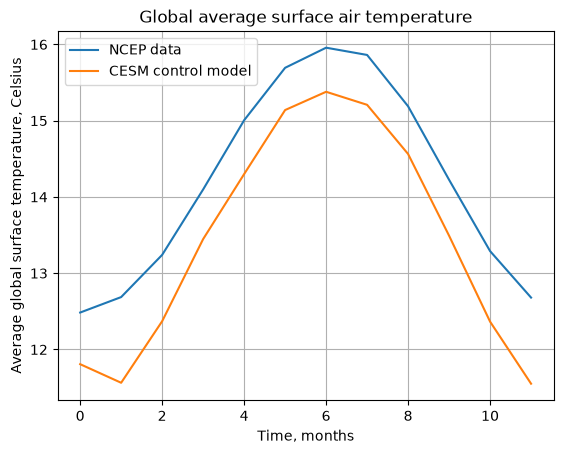

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# CESM trend
global_surf_temp_CESM = (atm_control.TREFHT * area_weight_factor).mean(dim=('lat', 'lon'))
# this is for 2 years, so only select the first 12 months. It is indexed by month

cos_lat = np.cos(np.deg2rad(ncep_air2m.lat))
area_weights = cos_lat / cos_lat.mean(dim='lat')

global_surf_temp_NCEP = (ncep_air2m.air * area_weights).mean(dim=('lat', 'lon'))

plt.figure()
plt.xlabel("Time, months")
plt.ylabel("Average global surface temperature, Celsius")
plt.plot(global_surf_temp_NCEP - 273.15, label="NCEP data")
plt.plot(global_surf_temp_CESM[0:12] - 273.15, label="CESM control model")
plt.title("Global average surface air temperature")
plt.legend()
plt.grid()

### Problem 2 Answers

This cycle could exist due to the Earth's tilt on its axis. If one hemisphere tends to absorb more solar radiation than the other, then the peak period of average surface temperature could correspond to the part of the year when that hemisphere is tilted towards the Sun. Some sources of this uneven absorption could be differences in polar ice coverage, differences in landmass area, or patterns in atmospheric transport. 

____________

## Credits

This notebook is part of [The Climate Laboratory](https://brian-rose.github.io/ClimateLaboratoryBook), an open-source textbook developed and maintained by [Brian E. J. Rose](https://www.atmos.albany.edu/facstaff/brose/), University at Albany.

It is licensed for free and open consumption under the
[Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/) license.

Development of these notes and the [climlab software](https://github.com/climlab/climlab) is partially supported by the National Science Foundation under award AGS-1455071 to Brian Rose. Any opinions, findings, conclusions or recommendations expressed here are mine and do not necessarily reflect the views of the National Science Foundation.
____________